# Hardware-agnostic MuTA: training and inference baseline

This notebook generates **Figure 1** and supporting diagnostics for the existing MuTA implementation **before any topological-qubit modifications**. It runs the actual outcome-corrected measurement patterns on the local QDK simulator. The optimizers, state preparations, inference, kernels, and SVM remain in Q#; Python schedules runs, saves models, and analyzes measurements.

**Reference design:** five independent seeds; all implemented training algorithms; saved-model inference on independent test data; fixed noisy-label datasets; resource-noise and shot sweeps. Every run is retained, including unsuccessful fits. The budgets are deliberately modest, so this is an empirical small-system baseline, **not** a reproduction of the paper's figures, proof of convergence, or demonstrated quantum advantage.

Source: [MuTA library documentation](../README.md), [paper coverage and conventions](../docs/paper-coverage.md), and Mantilla Calderon et al., [Measurement-based quantum machine learning](https://doi.org/10.1103/2snk-m8c6).

From the repository root, install `muta/requirements-notebook.txt` in the Python 3.12 environment. The README gives the headless execution command. **Run All retrains everything and overwrites the configured artifact directory; it does not load cached results or resume fits.** Allow substantial local simulator time (typically tens of minutes; the measured duration is saved in the manifest).

In [1]:
from dataclasses import asdict
import hashlib
import json
from pathlib import Path
import sys
from time import perf_counter

from IPython.display import Markdown, display
import matplotlib.pyplot as plt

%matplotlib inline

cwd = Path.cwd().resolve()
project = next((p / 'muta' for p in (cwd, *cwd.parents)
                if (p / 'muta' / 'benchmarks.py').is_file()), None)
if project is None:
    raise FileNotFoundError('Start this notebook from the quantum repository or its descendants.')
if str(project.parent) not in sys.path:
    sys.path.insert(0, str(project.parent))
from muta import benchmarks


In [2]:
config = benchmarks.Config(seeds=(11, 29, 47, 71, 101))
OUTPUT = project / 'artifacts' / 'reference'
started = perf_counter()

# Change Config fields explicitly for a new study; do not tune on these test results.
print(json.dumps(asdict(config), indent=2))


{
  "seeds": [
    11,
    29,
    47,
    71,
    101
  ],
  "train_states": 6,
  "test_states": 24,
  "train_shots": 16,
  "test_shots": 256,
  "gate_steps": 24,
  "entangler_steps": 24,
  "discrete_budget": 97,
  "classifier_train_per_family": 6,
  "classifier_test_per_family": 16,
  "classifier_steps": 12,
  "classifier_shots": 32,
  "teleport_steps": 16,
  "teleport_full_steps": 12,
  "teleport_shots": 8,
  "teleport_test_shots": 128,
  "noise_steps": 12,
  "kernel_train_per_class": 4,
  "kernel_test_per_class": 8,
  "kernel_shots": 128,
  "shot_sweep": [
    32,
    128,
    512
  ],
  "resource_noise": [
    0.0,
    0.01,
    0.03,
    0.05,
    0.1,
    0.2
  ]
}


## Protocol and interpretation

| Experiment | Training | Independent inference / control |
| --- | --- | --- |
| Single-qubit and entangling gates | Adam fits all 4 or 8 angles against independent circuit targets on fixed Haar states | Initial/fitted infidelity on new Haar states; fresh training-set reevaluation; MBQC/compiled-channel agreement |
| Restricted-angle gate | Greedy and neural DQN search all 4 slots over `{0, pi/4, pi/2}`; continuous Adam uses the same target | New Haar states; same maximum evaluation allowance, including Adam probes, not equal wall time |
| Quantum-state classifier | Joint fit of 4 tied basis angles and 6 polynomial coefficients; finite differences | Balanced accuracy by S1/S2 family; initialized model; task-informed known-QFI head |
| Teleportation | Either 4 correction angles with exact Bell stages, or all 20 angles from independent uniform random initialization | New Haar messages; exact instrument; all 4 outcome counts and failures retained |
| Quantum kernel SVM | Fixed MuTA embedding with measured SWAP kernels, then Q# SMO | Test-to-training similarities in saved training order; exact-expression kernel baseline; raw Gram eigenvalues |
| Noisy training | Matched-budget clean, bit-flip-label, Brownian-label, and resource-noise Adam fits | Clean held-out states; frozen clean/noise-trained models across resource noise |
| Shot / resource diagnostics | No additional fitting | Frozen classifier and kernel estimates across shots; logical graph counts across width/depth |

Seeds select independent named quantum and classical RNG streams using a stable SHA-256 scheme. Train/test amplitudes and feature/state parameters are saved, not merely regenerated from seeds. The one-qubit Haar split is intentionally shared across gate, noise, and teleportation tasks; no test sample enters a trainer. Classifier samples are balanced within each family and include points near SQL=2. Kernel datasets are balanced synthetic clusters and XOR clusters.

Training histories are **best observed, finite-shot losses** and include every derivative probe. Early stopping is disabled so the configured budgets, not an accidentally zero sampled loss, determine work. Adam updates require complete gradient steps, so its restricted-target run can use slightly fewer than the nominal maximum evaluations. Error bars and bands are **sample standard deviations across seeds**, not confidence intervals. Hyperparameters and the dataset design are fixed before viewing test results.

In [3]:
benchmarks.initialize()
training_sources = benchmarks.source_hashes()
datasets = benchmarks.draw_data(config)
models = {}
print(f'Drew disjoint train/test populations for {len(datasets)} seeds.')


Drew disjoint train/test populations for 5 seeds.


## Train the gate models

The one-qubit target is a fixed Z-Y-Z rotation. The entangling target is a locally dressed XX rotation, independently coded as a circuit and attainable with one connected two-wire MuTA layer. The restricted-angle target is a nontrivial Z-X-Z composition; **all four measurement slots are searched**, rather than fixing three slots as in the small runner examples. Angles always follow `pattern.Order`, not graph-vertex numbering.

In [4]:
models['gates'] = benchmarks.train_gates(datasets, config)


  single, seed 11: 217 evaluations, 6.8 s


  entangling, seed 11: 409 evaluations, 63.9 s

  restricted_adam, seed 11: 91 evaluations, 2.9 s


  restricted_greedy, seed 11: 97 evaluations, 3.1 s


  restricted_dqn, seed 11: 97 evaluations, 7.7 s


  single, seed 29: 217 evaluations, 7.0 s


... (15 outputs left out)

  entangling, seed 101: 409 evaluations, 66.0 s


  restricted_adam, seed 101: 91 evaluations, 2.9 s


  restricted_greedy, seed 101: 97 evaluations, 3.1 s


  restricted_dqn, seed 101: 97 evaluations, 7.9 s


## Train the classifier and teleportation instrument

Classifier labels come from the analytic QFI of the prepared state under `(Z0 + Z1)/2`, with SQL=2 and Heisenberg limit=4. The learned polynomial head is **not** initialized to that analytic formula. Tied angles and a nonlinear margin objective require finite differences, not a direct parameter shift of the complete classifier loss.

The correction-only teleportation condition has a strong, explicitly known Bell-stage inductive bias. The full 20-angle condition does not: every initial angle is sampled uniformly in `[-pi, pi]`. The exact instrument is evaluated only as a control, never used for choosing the cold-start model.

In [5]:
models['classifier'] = benchmarks.train_classifiers(datasets, config)


  classifier, seed 11: 253 evaluations, 89.0 s


  classifier, seed 29: 253 evaluations, 89.2 s

  classifier, seed 47: 253 evaluations, 88.8 s


  classifier, seed 71: 253 evaluations, 88.2 s


  classifier, seed 101: 253 evaluations, 93.1 s


In [6]:
models['teleportation'] = benchmarks.train_teleportation(datasets, config)


  teleport_corrections, seed 11: 145 evaluations, 33.0 s


  teleport_full, seed 11: 493 evaluations, 103.1 s

  teleport_corrections, seed 29: 145 evaluations, 28.5 s

  teleport_full, seed 29: 493 evaluations, 97.1 s


  teleport_corrections, seed 47: 145 evaluations, 29.3 s


  teleport_full, seed 47: 493 evaluations, 104.8 s

  teleport_corrections, seed 71: 145 evaluations, 32.6 s


  teleport_full, seed 71: 493 evaluations, 113.7 s

  teleport_corrections, seed 101: 145 evaluations, 29.8 s


  teleport_full, seed 101: 493 evaluations, 103.1 s


## Train with corruption and fit the kernel SVMs

All noise conditions have the same training states, initialization, shots, Adam settings, and evaluation budget. Bit-flip probabilities are 0.1/0.3. Brownian time steps are 0.1/0.3 with three increments and two symmetric Trotter steps; these are **not** probabilities. Every sampled label-noise program is fixed throughout its fit and saved verbatim. With only a few training labels, a bit-flip draw can legitimately contain no flipped labels; such runs are retained.

Resource depolarization uses total nonidentity Pauli probability `p` (X/Y/Z each with probability `p/3`), with training levels 0.01/0.05. It is sampled once on the full entangled resource on each execution. The later sweep uses frozen clean-trained and p=0.05-trained models; it never refits at the inference noise level.

Kernel SVM fitting stores both the dual model and the ordered training points. The exact comparator uses the **same feature map**, not a different classical kernel. Finite-shot SWAP estimates may be negative and the Gram matrix may be indefinite; neither is silently clipped or repaired. Stable SMO passes are reported, not treated as a proof of optimality.

In [7]:
models['noise'] = benchmarks.train_noise(datasets, config)


  noise:clean, seed 11: 109 evaluations, 3.5 s


  noise:bitflip_0.1, seed 11: 109 evaluations, 3.5 s

  noise:bitflip_0.3, seed 11: 109 evaluations, 3.5 s

  noise:brownian_0.1, seed 11: 109 evaluations, 6.5 s


  noise:brownian_0.3, seed 11: 109 evaluations, 6.5 s


  noise:resource_0.01, seed 11: 109 evaluations, 3.5 s

... (25 outputs left out)

  noise:brownian_0.1, seed 101: 109 evaluations, 6.5 s

  noise:brownian_0.3, seed 101: 109 evaluations, 6.5 s


  noise:resource_0.01, seed 101: 109 evaluations, 3.5 s


  noise:resource_0.05, seed 101: 109 evaluations, 3.5 s


In [8]:
models['kernel'] = benchmarks.train_kernels(datasets, config)
if benchmarks.source_hashes() != training_sources:
    raise RuntimeError('Sources changed during training; restart the notebook.')
benchmarks.save_training(OUTPUT, datasets, models, config)
print(f'Saved {sum(len(group) for group in models.values())} fitted models and their datasets.')


  kernel:clusters:shots, seed 11: 13 SMO passes, 24.5 s


  kernel:clusters:exact, seed 11: 13 SMO passes, 0.0 s


  kernel:xor:shots, seed 11: 22 SMO passes, 24.5 s


  kernel:xor:exact, seed 11: 11 SMO passes, 0.0 s


  kernel:clusters:shots, seed 29: 11 SMO passes, 24.5 s


  kernel:clusters:exact, seed 29: 14 SMO passes, 0.0 s

... (11 outputs left out)

  kernel:clusters:exact, seed 101: 22 SMO passes, 0.0 s


  kernel:xor:shots, seed 101: 11 SMO passes, 24.6 s

  kernel:xor:exact, seed 101: 15 SMO passes, 0.0 s


Saved 95 fitted models and their datasets.


## Cold-context inference: no retraining

Discard the in-memory training objects, initialize a fresh isolated QDK context, and reload JSON. Source/configuration and dataset hashes must agree before inference is allowed. The following cells call only inference operations; they do not invoke an optimizer, select a checkpoint, tune a threshold, or choose a seed.

For gates and teleportation, the metric is projection infidelity against the independently prepared target state. For classification it is balanced accuracy, with fixed thresholds 2.0 (state classifier) and 0.0 (SVM score). All held-out states are re-prepared for every shot. Runtime measurements are local simulator times, **not QPU latency**.

In [9]:
del models, datasets
benchmarks.initialize()
datasets, models = benchmarks.load_training(OUTPUT, config)
results = {}
print('Loaded saved models in a fresh QDK context; no trainer is called below.')


Loaded saved models in a fresh QDK context; no trainer is called below.


In [10]:
results['gates'] = benchmarks.infer_gates(models['gates'], datasets, config)


  single, seed 11: held-out infidelity 0.0322


  entangling, seed 11: held-out infidelity 0.0050


  restricted_adam, seed 11: held-out infidelity 0.0184


  restricted_greedy, seed 11: held-out infidelity 0.0000


  restricted_dqn, seed 11: held-out infidelity 0.0557


  single, seed 29: held-out infidelity 0.0091


... (15 outputs left out)

  entangling, seed 101: held-out infidelity 0.0247

  restricted_adam, seed 101: held-out infidelity 0.0996


  restricted_greedy, seed 101: held-out infidelity 0.0000


  restricted_dqn, seed 101: held-out infidelity 0.0545


In [11]:
results['classifier'] = benchmarks.infer_classifiers(models['classifier'], datasets, config)


  classifier, seed 11: held-out balanced accuracy 0.688


  classifier, seed 29: held-out balanced accuracy 0.625


  classifier, seed 47: held-out balanced accuracy 0.562


  classifier, seed 71: held-out balanced accuracy 0.469


  classifier, seed 101: held-out balanced accuracy 0.781


In [12]:
results['teleportation'], results['teleportation_reference'] = benchmarks.infer_teleportation(
    models['teleportation'], datasets, config
)


  teleport_corrections, seed 11: held-out infidelity 0.0459


  teleport_full, seed 11: held-out infidelity 0.3092

  teleport_corrections, seed 29: held-out infidelity 0.0212


  teleport_full, seed 29: held-out infidelity 0.4857


  teleport_corrections, seed 47: held-out infidelity 0.0348


  teleport_full, seed 47: held-out infidelity 0.3167

  teleport_corrections, seed 71: held-out infidelity 0.0902


  teleport_full, seed 71: held-out infidelity 0.4814


  teleport_corrections, seed 101: held-out infidelity 0.0332


  teleport_full, seed 101: held-out infidelity 0.4310


In [13]:
results['kernel'] = benchmarks.infer_kernels(models['kernel'], datasets, config)


  kernel:clusters:shots, seed 11: held-out balanced accuracy 1.000


  kernel:clusters:exact, seed 11: held-out balanced accuracy 1.000


  kernel:xor:shots, seed 11: held-out balanced accuracy 0.938


  kernel:xor:exact, seed 11: held-out balanced accuracy 0.875


  kernel:clusters:shots, seed 29: held-out balanced accuracy 1.000

  kernel:clusters:exact, seed 29: held-out balanced accuracy 1.000


... (10 outputs left out)

  kernel:clusters:shots, seed 101: held-out balanced accuracy 1.000


  kernel:clusters:exact, seed 101: held-out balanced accuracy 1.000


  kernel:xor:shots, seed 101: held-out balanced accuracy 0.875


  kernel:xor:exact, seed 101: held-out balanced accuracy 1.000


In [14]:
results['noise'] = benchmarks.infer_noise(models['noise'], datasets, config)


  noise:clean, seed 11: clean held-out infidelity 0.0348


  noise:bitflip_0.1, seed 11: clean held-out infidelity 0.1271


  noise:bitflip_0.3, seed 11: clean held-out infidelity 0.0262


  noise:brownian_0.1, seed 11: clean held-out infidelity 0.0418


  noise:brownian_0.3, seed 11: clean held-out infidelity 0.0819


  noise:resource_0.01, seed 11: clean held-out infidelity 0.0104


... (25 outputs left out)

  noise:brownian_0.1, seed 101: clean held-out infidelity 0.0257


  noise:brownian_0.3, seed 101: clean held-out infidelity 0.1421

  noise:resource_0.01, seed 101: clean held-out infidelity 0.0256


  noise:resource_0.05, seed 101: clean held-out infidelity 0.0363


## Shot sensitivity and logical resources

The classifier shot sweep changes only the number of inference shots; the saved angles/head stay fixed. The kernel sweep compares measured held-out overlaps with the exact expression. For a SWAP estimate `K_hat = 2 n0 / shots - 1`, the variance is `(1 - K^2) / shots`; the diagnostic shows the root mean of these variances alongside observed RMSE. It is a kernel-estimator calibration, **not** an SVM retraining sweep.

The resource table counts graph vertices, edges, measured angles, causal slices, and compiled gates. Larger graphs are constructed classically for this table, not simulated. These are logical algorithm counts, not a topological encoding or physical-qubit estimate.

In [15]:
results['shots'] = benchmarks.shot_diagnostics(models['classifier'], datasets, config)
results['resources'] = benchmarks.logical_resources()
if benchmarks.source_hashes() != training_sources:
    raise RuntimeError('Sources changed during inference; restart the notebook.')
benchmarks.validate_results(models, results, datasets, config)
benchmarks.write_json(OUTPUT / 'results.json', results)
summary = benchmarks.summary_rows(results)
benchmarks.write_summary(OUTPUT / 'summary.csv', summary)
print('Complete experiment matrix, model reload, channel controls, and outcome accounting verified.')
display(Markdown('| Wires | Layers | Vertices | Edges | Angles | Causal slices | Compiled gates |\n'
                 '| ---: | ---: | ---: | ---: | ---: | ---: | ---: |\n' + '\n'.join(
    '| ' + ' | '.join(str(row[key]) for key in
                     ('width', 'depth', 'vertices', 'edges', 'angles', 'flow_slices', 'compiled_gates')) + ' |'
    for row in results['resources'])))


Complete experiment matrix, model reload, channel controls, and outcome accounting verified.


| Wires | Layers | Vertices | Edges | Angles | Causal slices | Compiled gates |
| ---: | ---: | ---: | ---: | ---: | ---: | ---: |
| 1 | 1 | 5 | 4 | 4 | 4 | 8 |
| 1 | 2 | 9 | 8 | 8 | 8 | 16 |
| 1 | 3 | 13 | 12 | 12 | 12 | 24 |
| 2 | 1 | 10 | 10 | 8 | 6 | 18 |
| 2 | 2 | 18 | 20 | 16 | 12 | 36 |
| 2 | 3 | 26 | 30 | 24 | 18 | 54 |
| 3 | 1 | 15 | 16 | 12 | 6 | 28 |
| 3 | 2 | 27 | 32 | 24 | 12 | 56 |
| 3 | 3 | 39 | 48 | 36 | 18 | 84 |
| 4 | 1 | 20 | 22 | 16 | 6 | 38 |
| 4 | 2 | 36 | 44 | 32 | 12 | 76 |
| 4 | 3 | 52 | 66 | 48 | 18 | 114 |

## Figure 1 and supporting diagnostics

The main figure separates training trajectories from held-out inference and compares learned models with appropriate controls. Each point in panels b-e is an individual seed; error bars and training bands are one sample SD across seeds. The diagnostic figure exposes corruption sensitivity, classifier boundary behavior, shot sensitivity, and logical graph growth. Inference p sweeps are not training curves. Panels use task-specific scales and budgets, not a shared physical cost model.

Each figure is exported as **vector PDF**, **editable-text SVG**, and **300-dpi PNG**. The next cell displays exactly the figures written to disk.

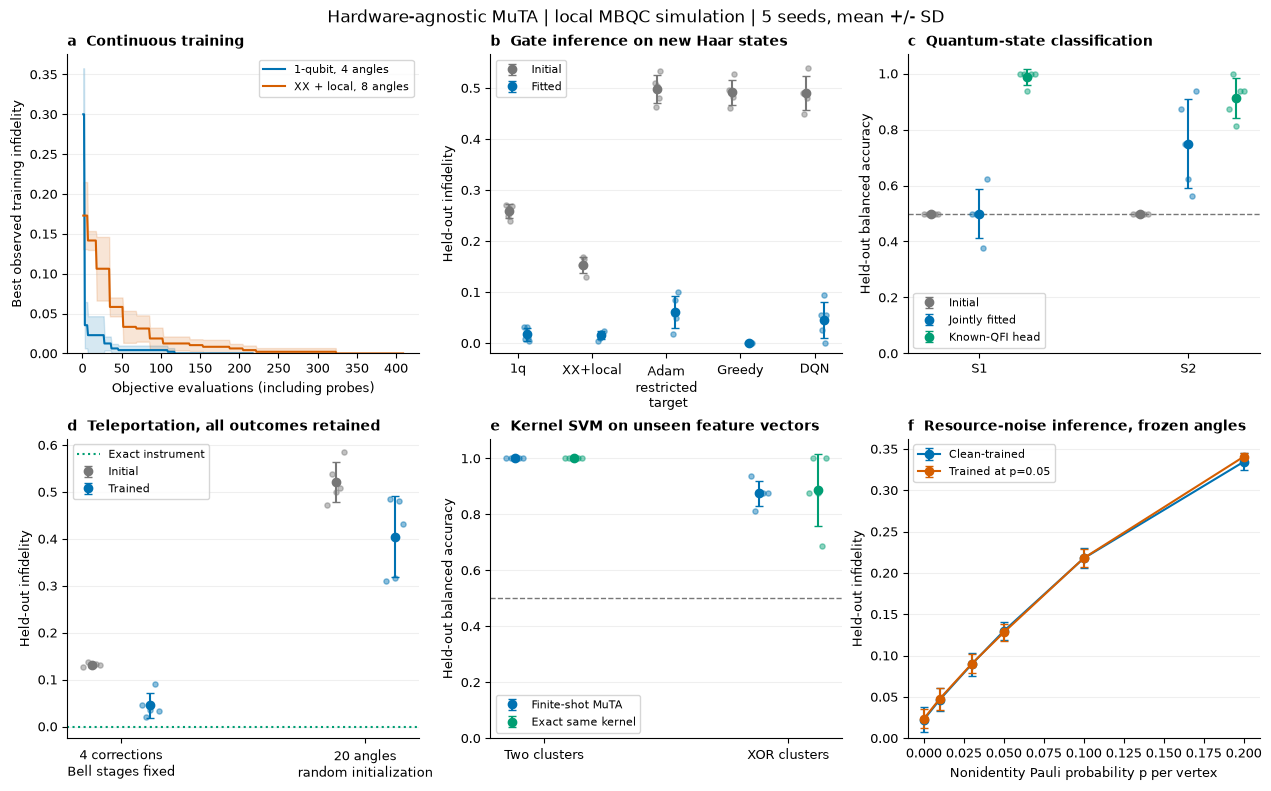

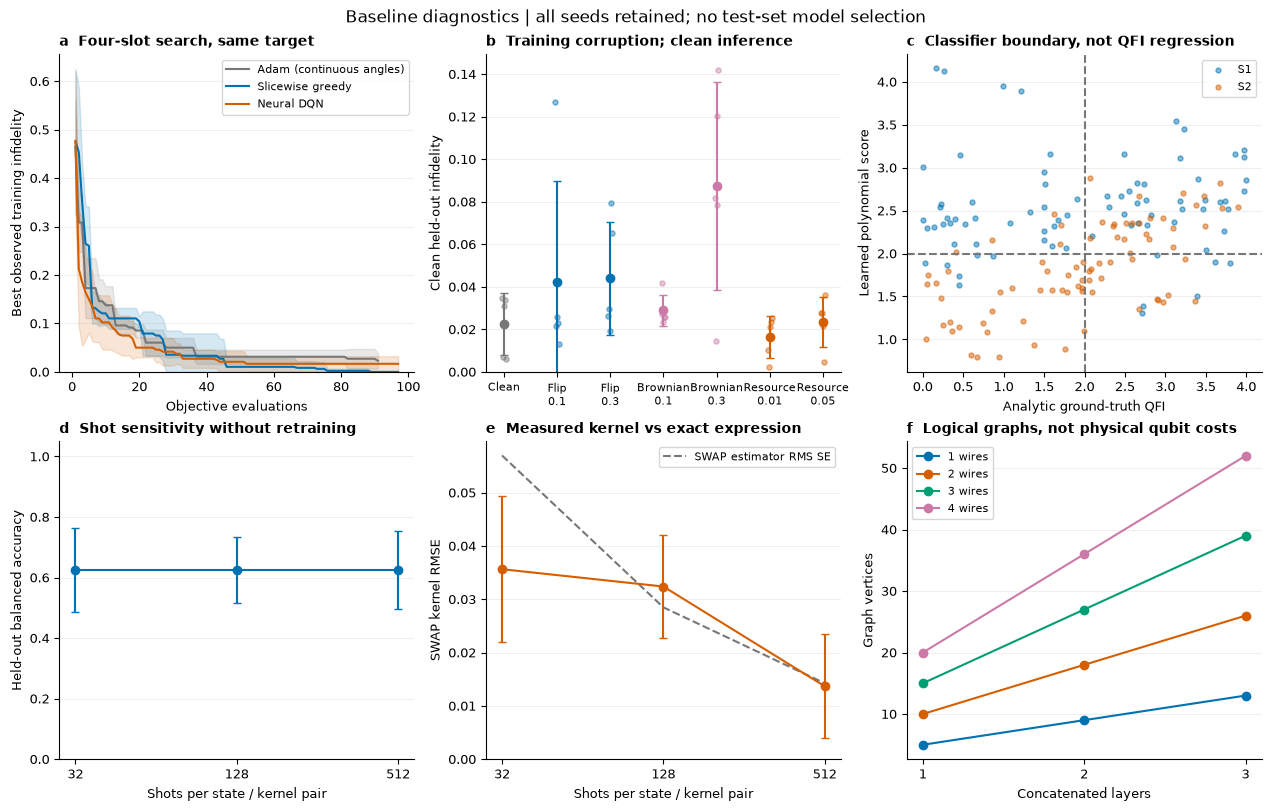

Exported: figure-1.pdf, figure-1.svg, figure-1.png, diagnostics.pdf, diagnostics.svg, diagnostics.png


In [3]:
from matplotlib.ticker import NullLocator

figures = benchmarks.make_figures(models, results, datasets, config)
for ax in figures['diagnostics'].axes:
    if ax.get_xscale() == 'log':
        ax.xaxis.set_minor_locator(NullLocator())
figure_paths = benchmarks.save_figures(OUTPUT, figures)
for figure in figures.values():
    display(figure)
    plt.close(figure)
print('Exported: ' + ', '.join(path.name for path in figure_paths))


In [17]:
display(Markdown(benchmarks.evaluation_markdown(models, results, config)))
caption = benchmarks.figure_caption(config)
(OUTPUT / 'figure-1-caption.txt').write_text(caption + '\n', encoding='utf-8')
display(Markdown('### Suggested Figure 1 caption\n\n' + caption))


## Evaluation of this executed baseline

All **95 fits** across **5 seeds** are retained. Inference uses reloaded models, independent held-out data, and fresh quantum/classical RNG streams. Values below are means +/- sample SD across seeds.

| Experiment | Held-out metric | Initial | Fitted / reference |
| --- | --- | --- | --- |
| single | held-out infidelity | 0.259 +/- 0.014 | 0.017 +/- 0.013 |
| entangling | held-out infidelity | 0.154 +/- 0.015 | 0.015 +/- 0.008 |
| restricted_adam | held-out infidelity | 0.498 +/- 0.028 | 0.061 +/- 0.032 |
| restricted_greedy | held-out infidelity | 0.492 +/- 0.024 | 0.000 +/- 0.000 |
| restricted_dqn | held-out infidelity | 0.490 +/- 0.033 | 0.046 +/- 0.036 |
| initial:S1 | balanced accuracy | - | 0.500 +/- 0.000 |
| initial:S2 | balanced accuracy | - | 0.500 +/- 0.000 |
| trained:S1 | balanced accuracy | - | 0.500 +/- 0.088 |
| trained:S2 | balanced accuracy | - | 0.750 +/- 0.159 |
| qfi_reference:S1 | balanced accuracy | - | 0.988 +/- 0.028 |
| qfi_reference:S2 | balanced accuracy | - | 0.912 +/- 0.071 |
| teleport_corrections | held-out infidelity | 0.132 +/- 0.004 | 0.045 +/- 0.027 |
| teleport_full | held-out infidelity | 0.521 +/- 0.043 | 0.405 +/- 0.087 |
| clusters:shots | balanced accuracy | - | 1.000 +/- 0.000 |
| clusters:exact | balanced accuracy | - | 1.000 +/- 0.000 |
| xor:shots | balanced accuracy | - | 0.875 +/- 0.044 |
| xor:exact | balanced accuracy | - | 0.887 +/- 0.128 |
| clean | clean held-out infidelity | - | 0.023 +/- 0.015 |
| bitflip_0.1 | clean held-out infidelity | - | 0.042 +/- 0.048 |
| bitflip_0.3 | clean held-out infidelity | - | 0.044 +/- 0.027 |
| brownian_0.1 | clean held-out infidelity | - | 0.029 +/- 0.007 |
| brownian_0.3 | clean held-out infidelity | - | 0.087 +/- 0.049 |
| resource_0.01 | clean held-out infidelity | - | 0.017 +/- 0.010 |
| resource_0.05 | clean held-out infidelity | - | 0.024 +/- 0.012 |

### What the results support

- Single-qubit Adam improves held-out infidelity in **5/5** runs. Mean held-out infidelity is **0.0175**.
- Entangling-gate Adam improves held-out infidelity in **5/5** runs. Mean held-out infidelity is **0.0154**.
- Four-correction teleportation improves in **5/5** runs; mean held-out infidelity is **0.0451**. The exact instrument has no observed projection failures.
- Cold-start, 20-angle teleportation improves in **5/5** runs; mean held-out infidelity is **0.4048**. The exact instrument has no observed projection failures.
- The jointly trained state classifier reaches **0.625** pooled balanced accuracy versus **0.950** for the task-informed, known-QFI measurement baseline. The fitted score is not a calibrated QFI estimate or probability.
- **10/10** shot-estimated training Gram matrices have a negative eigenvalue (minimum **-0.1907**); **0** SVM fits reach the iteration cap without eight stable passes. Matrices are not clipped or silently projected to PSD; even a stable pass count is not an optimality proof.
- Fresh, higher-shot training-set reevaluation exceeds the selected training incumbent by **0.0166** infidelity on average. Best-observed training curves are selection-biased and must not be reported as test fidelity.
- Training with resource p=0.05 changes clean held-out infidelity by **+0.0011** relative to the matched-budget clean control. The noise curve evaluates these same frozen models; it does not retrain at each p.

### Limits and interpretation for Figure 1

- This is a small, budgeted simulator reference, not a reproduction of the paper's numerical experiments, a convergence guarantee, or evidence of quantum learning advantage. Five seeds characterize this run, not a publication-grade confidence interval.
- The XX target is attainable in one connected layer; all eight angles are trainable. Greedy/DQN use all four slots and alphabet {0, pi/4, pi/2}; their Adam control uses continuous angles on the same target. No claim of equal wall-clock work is made.
- The four-correction teleportation experiment assumes exact Bell stages. Only the 20-angle condition is a random cold start; neither the known solution nor the test loss is used to select its model. No instrument outcomes are postselected.
- Classifier states are class-balanced within each family, including states near SQL=2. The kernel datasets are synthetic balanced clusters/XOR, not the paper's datasets; the MuTA feature map is fixed and only the SVM is fitted.
- Bit-flip programs and Brownian programs are sampled once per training label and saved. Brownian levels are time steps with three increments and two Trotter steps, not error probabilities. Resource p is total nonidentity Pauli probability per graph vertex (p/3 each for X, Y, Z), sampled anew on every execution.
- Zero sampled errors do not establish a zero true error rate. Error bars describe between-seed variation, combining training randomness, dataset draws, and finite shots; they are not independent per-shot confidence intervals.
- Graph counts, MBQC execution counts, and simulator wall times are not physical qubit costs or QPU latency. No topological encoding, Majorana operations, logical error correction, device connectivity, or hardware execution is included.

### Recorded training work

| Family | Fits | MBQC pattern executions | Simulator fit time (s) |
| --- | ---: | ---: | ---: |
| gates | 25 | 437,280 | 429.1 |
| classifier | 5 | 485,760 | 448.3 |
| teleportation | 10 | 459,360 | 674.9 |
| noise | 35 | 366,240 | 152.4 |
| kernel | 20 | 71,680 | 244.8 |

### Suggested Figure 1 caption

Figure 1. Hardware-agnostic MuTA baseline under local QDK MBQC simulation (5 independent seeds; means and sample standard deviations). (a) Best observed continuous-training infidelity versus objective evaluations, including derivative probes. (b) Initial and fitted gate infidelity on independent Haar states; the last three conditions share an attainable four-slot restricted-angle target, but the Adam control has continuous angles. (c) Held-out balanced accuracy for both quantum-state families, compared with initialization and a task-informed known-QFI head. (d) Teleportation with four fitted correction angles and fixed Bell stages, or all twenty angles fitted from a random initialization; all measurement outcomes are retained. (e) SVM prediction on unseen cluster/XOR points using the finite-shot MuTA kernel or its exact expression. (f) Frozen clean-trained and noise-trained gates under resource depolarization, with total nonidentity Pauli probability p per vertex. Individual dots in (b)-(e) show all seeds. Budgets and data sizes differ by task and are specified in the notebook and machine-readable configuration. Training incumbents are noisy and selection-biased; panels (b)-(f) use fresh inference shots without test-set model selection. These small demonstrations do not establish quantum advantage, reproduce published numerical figures, or model topological-qubit hardware.

In [18]:
manifest = benchmarks.provenance(config, perf_counter() - started)
notebook = json.loads((project / 'notebooks' / 'hardware_agnostic_baseline.ipynb').read_text())
source = [(cell['cell_type'], cell['source']) for cell in notebook['cells']]
manifest['notebook_source_sha256'] = hashlib.sha256(json.dumps(source).encode()).hexdigest()
artifact_names = ['datasets.json', 'models.json', 'results.json', 'summary.csv',
                  'figure-1-caption.txt', *[path.name for path in figure_paths]]
manifest['artifacts_sha256'] = {
    name: hashlib.sha256((OUTPUT / name).read_bytes()).hexdigest() for name in artifact_names
}
benchmarks.write_json(OUTPUT / 'manifest.json', manifest)
print(f"Completed in {manifest['wall_seconds'] / 60:.1f} minutes on the local simulator.")
print('Saved datasets, fitted models, raw inference, summary CSV, figures, caption, and provenance.')
print(json.dumps(manifest['packages'], indent=2))


Completed in 72.9 minutes on the local simulator.
Saved datasets, fitted models, raw inference, summary CSV, figures, caption, and provenance.
{
  "qdk": "1.32.0",
  "numpy": "2.5.4",
  "matplotlib": "3.11.2",
  "nbformat": "5.11.1",
  "nbclient": "0.11.0",
  "nbconvert": "7.17.2",
  "ipykernel": "7.4.0"
}
